In [2]:
# ==============================================================================
# SEL 1: IMPORT LIBRARY & MUAT DATASET HASIL SPLIT
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Muat data latih dan uji (80:20 kronologis)
train_sarima = pd.read_csv('train_sarima.csv', index_col='TglPeriksa', parse_dates=True)
test_sarima = pd.read_csv('test_sarima.csv', index_col='TglPeriksa', parse_dates=True)

train_prophet = pd.read_csv('train_prophet.csv')
test_prophet = pd.read_csv('test_prophet.csv')
train_prophet['ds'] = pd.to_datetime(train_prophet['ds'])
test_prophet['ds'] = pd.to_datetime(test_prophet['ds'])

y_train = train_sarima['Jumlah_Pendonor'].values
y_test = test_sarima['Jumlah_Pendonor'].values
horizon = len(y_test)

print(f"Data Latih: {len(y_train)} hari | Data Uji: {horizon} hari")

Data Latih: 194 hari | Data Uji: 49 hari


In [3]:
# ==============================================================================
# SEL 2: FUNGSI EVALUASI (MAE, RMSE, MASE) & BASELINE SEASONAL NAIVE (s=7)
# ==============================================================================
def evaluasi_model(y_train_arr, y_true_arr, y_pred_arr, m=7):
    mae = mean_absolute_error(y_true_arr, y_pred_arr)
    rmse = root_mean_squared_error(y_true_arr, y_pred_arr)
    scale = np.mean(np.abs(y_train_arr[m:] - y_train_arr[:-m]))
    mase = mae / scale
    return {'MAE': mae, 'RMSE': rmse, 'MASE': mase}

# Prediksi Seasonal Naive (mengulang siklus 7 hari terakhir dari data latih)
last_week = y_train[-7:]
pred_snaive = np.tile(last_week, int(np.ceil(horizon / 7)))[:horizon]

hasil_snaive = evaluasi_model(y_train, y_test, pred_snaive, m=7)
print("Evaluasi Seasonal Naive (s=7):", hasil_snaive)

Evaluasi Seasonal Naive (s=7): {'MAE': 18.653061224489797, 'RMSE': 24.090814576073917, 'MASE': np.float64(0.9654366036478251)}


,Model,AIC,BIC,LjungBox_p_lag7,LjungBox_p_lag14
4,"SARIMA(0, 1, 2)x(0, 1, 1, 7)",1571.40,1584.08,0.6827,0.8442
1,"SARIMA(1, 1, 1)x(0, 1, 1, 7)",1578.79,1591.50,0.6744,0.8226
2,"SARIMA(1, 1, 1)x(1, 1, 1, 7)",1579.69,1595.57,0.6419,0.8112
3,"SARIMA(2, 1, 1)x(0, 1, 1, 7)",1580.79,1596.67,0.6795,0.8258
0,"SARIMA(0, 1, 1)x(0, 1, 1, 7)",1580.92,1590.45,0.1569,0.3900



Model SARIMA Terpilih (AIC Terendah): SARIMA(0, 1, 2)x(0, 1, 1, 7)
                                      SARIMAX Results                                      
Dep. Variable:                     Jumlah_Pendonor   No. Observations:                  194
Model:             SARIMAX(0, 1, 2)x(0, 1, [1], 7)   Log Likelihood                -781.698
Date:                             Mon, 23 Nov 2026   AIC                           1571.397
Time:                                     14:18:21   BIC                           1584.079
Sample:                                 01-01-2026   HQIC                          1576.540
                                      - 07-13-2026                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7526      0.085     -

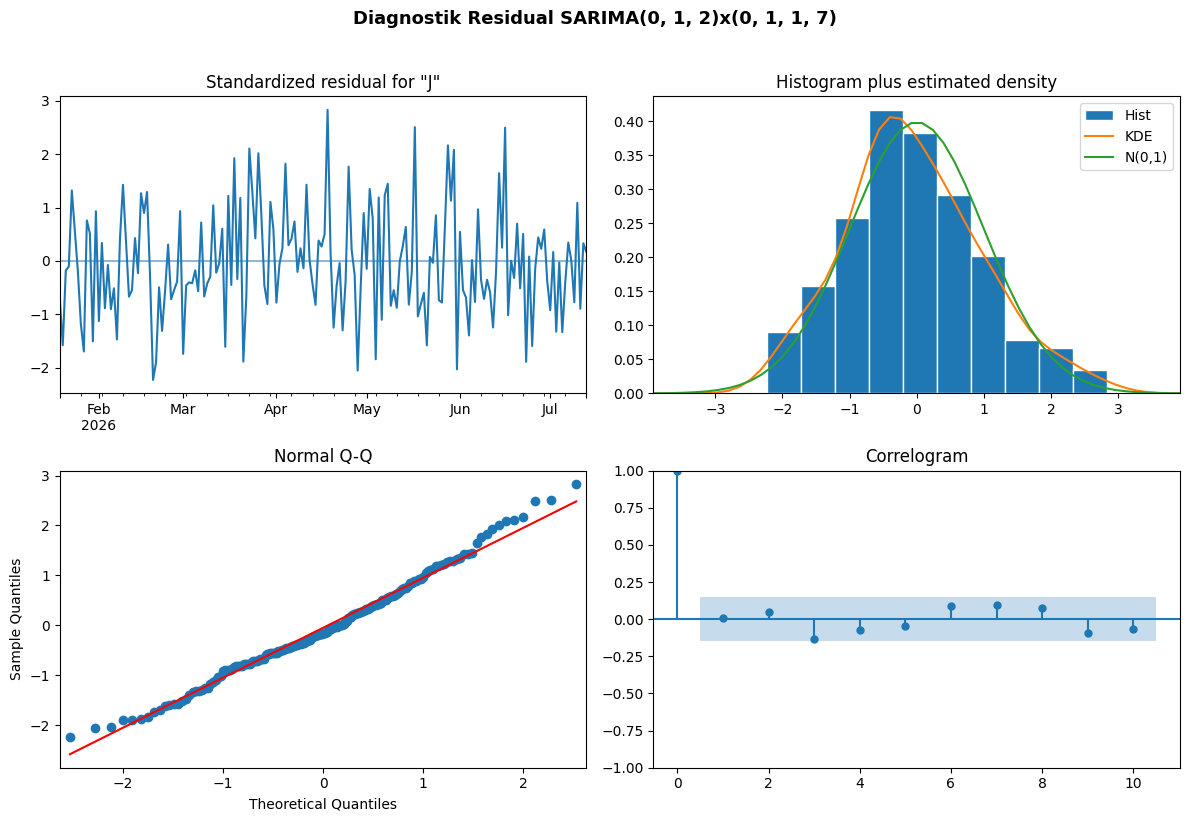

In [4]:
# ==============================================================================
# SEL 3: SELEKSI KANDIDAT SARIMA & DIAGNOSTIK RESIDUAL
# ==============================================================================
kandidat_sarima = [
    ((0, 1, 1), (0, 1, 1, 7)),
    ((1, 1, 1), (0, 1, 1, 7)),
    ((1, 1, 1), (1, 1, 1, 7)),
    ((2, 1, 1), (0, 1, 1, 7)),
    ((0, 1, 2), (0, 1, 1, 7)),
]

ringkasan_aic = []
model_terfit = {}

for order, seasonal_order in kandidat_sarima:
    nama = f"SARIMA{order}x{seasonal_order}"
    model = SARIMAX(
        train_sarima['Jumlah_Pendonor'],
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False
    )
    fit = model.fit(disp=False)
    lb_test = acorr_ljungbox(fit.resid.dropna(), lags=[7, 14], return_df=True)
    ringkasan_aic.append({
        'Model': nama,
        'AIC': round(fit.aic, 2),
        'BIC': round(fit.bic, 2),
        'LjungBox_p_lag7': round(lb_test['lb_pvalue'].iloc[0], 4),
        'LjungBox_p_lag14': round(lb_test['lb_pvalue'].iloc[1], 4)
    })
    model_terfit[nama] = fit

df_seleksi = pd.DataFrame(ringkasan_aic).sort_values(by='AIC')
display(df_seleksi)

# Ambil model dengan AIC terendah
nama_sarima_terbaik = df_seleksi.iloc[0]['Model']
fit_sarima_terbaik = model_terfit[nama_sarima_terbaik]
print(f"\nModel SARIMA Terpilih (AIC Terendah): {nama_sarima_terbaik}")
print(fit_sarima_terbaik.summary())

# Plot Diagnostik Residual Model SARIMA Terpilih
fig = fit_sarima_terbaik.plot_diagnostics(figsize=(12, 8))
plt.suptitle(f'Diagnostik Residual {nama_sarima_terbaik}', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('diagnostik_residual_sarima.png', dpi=300, bbox_inches='tight')
plt.show()

# Peramalan 49 hari ke depan
forecast_sarima_res = fit_sarima_terbaik.get_forecast(steps=horizon)
pred_sarima = forecast_sarima_res.predicted_mean.values
ci_sarima = forecast_sarima_res.conf_int()

hasil_sarima = evaluasi_model(y_train, y_test, pred_sarima, m=7)

14:18:25 - cmdstanpy - INFO - Chain [1] start processing
14:18:26 - cmdstanpy - INFO - Chain [1] done processing


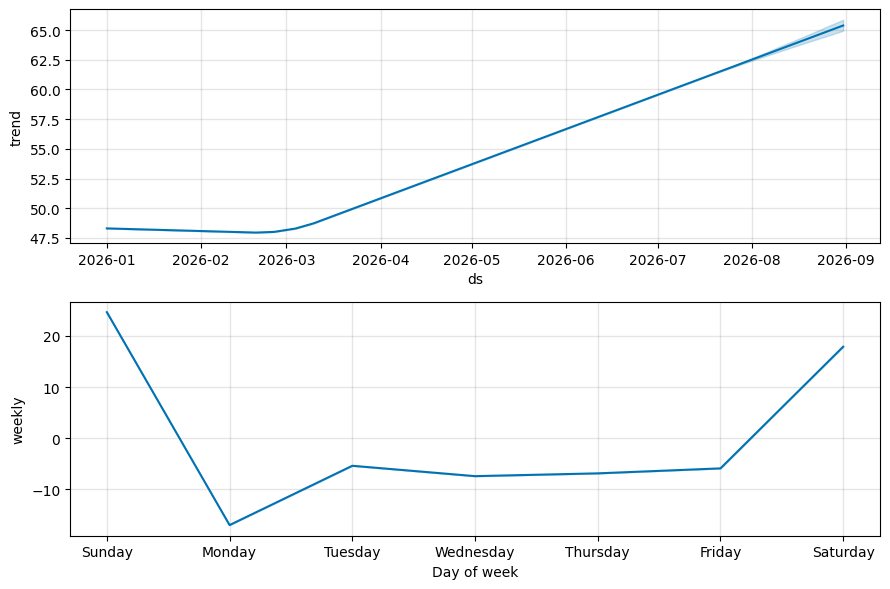

In [5]:
# ==============================================================================
# SEL 4: PELATIHAN & PERAMALAN META PROPHET (MUSIMAN MINGGUAN s=7)
# ==============================================================================
model_prophet = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode='additive'
)
model_prophet.fit(train_prophet)

future = model_prophet.make_future_dataframe(periods=horizon, freq='D')
forecast_prophet = model_prophet.predict(future)

# Ambil 49 hari periode uji
forecast_prophet_test = forecast_prophet.iloc[-horizon:].copy()
pred_prophet = forecast_prophet_test['yhat'].values

hasil_prophet = evaluasi_model(y_train, y_test, pred_prophet, m=7)

# Plot Komponen Meta Prophet (Opsional untuk analisis pembahasan)
fig_comp = model_prophet.plot_components(forecast_prophet)
plt.tight_layout()
plt.show()

=== TABEL EVALUASI KINERJA PERAMALAN (49 HARI UJI) ===


,Model,MAE,RMSE,MASE
0,Seasonal Naive (s=7),18.6531,24.0908,0.9654
1,"SARIMA(0, 1, 2)x(0, 1, 1, 7)",16.6868,22.8345,0.8637
2,Meta Prophet (s=7),16.0608,21.3494,0.8313


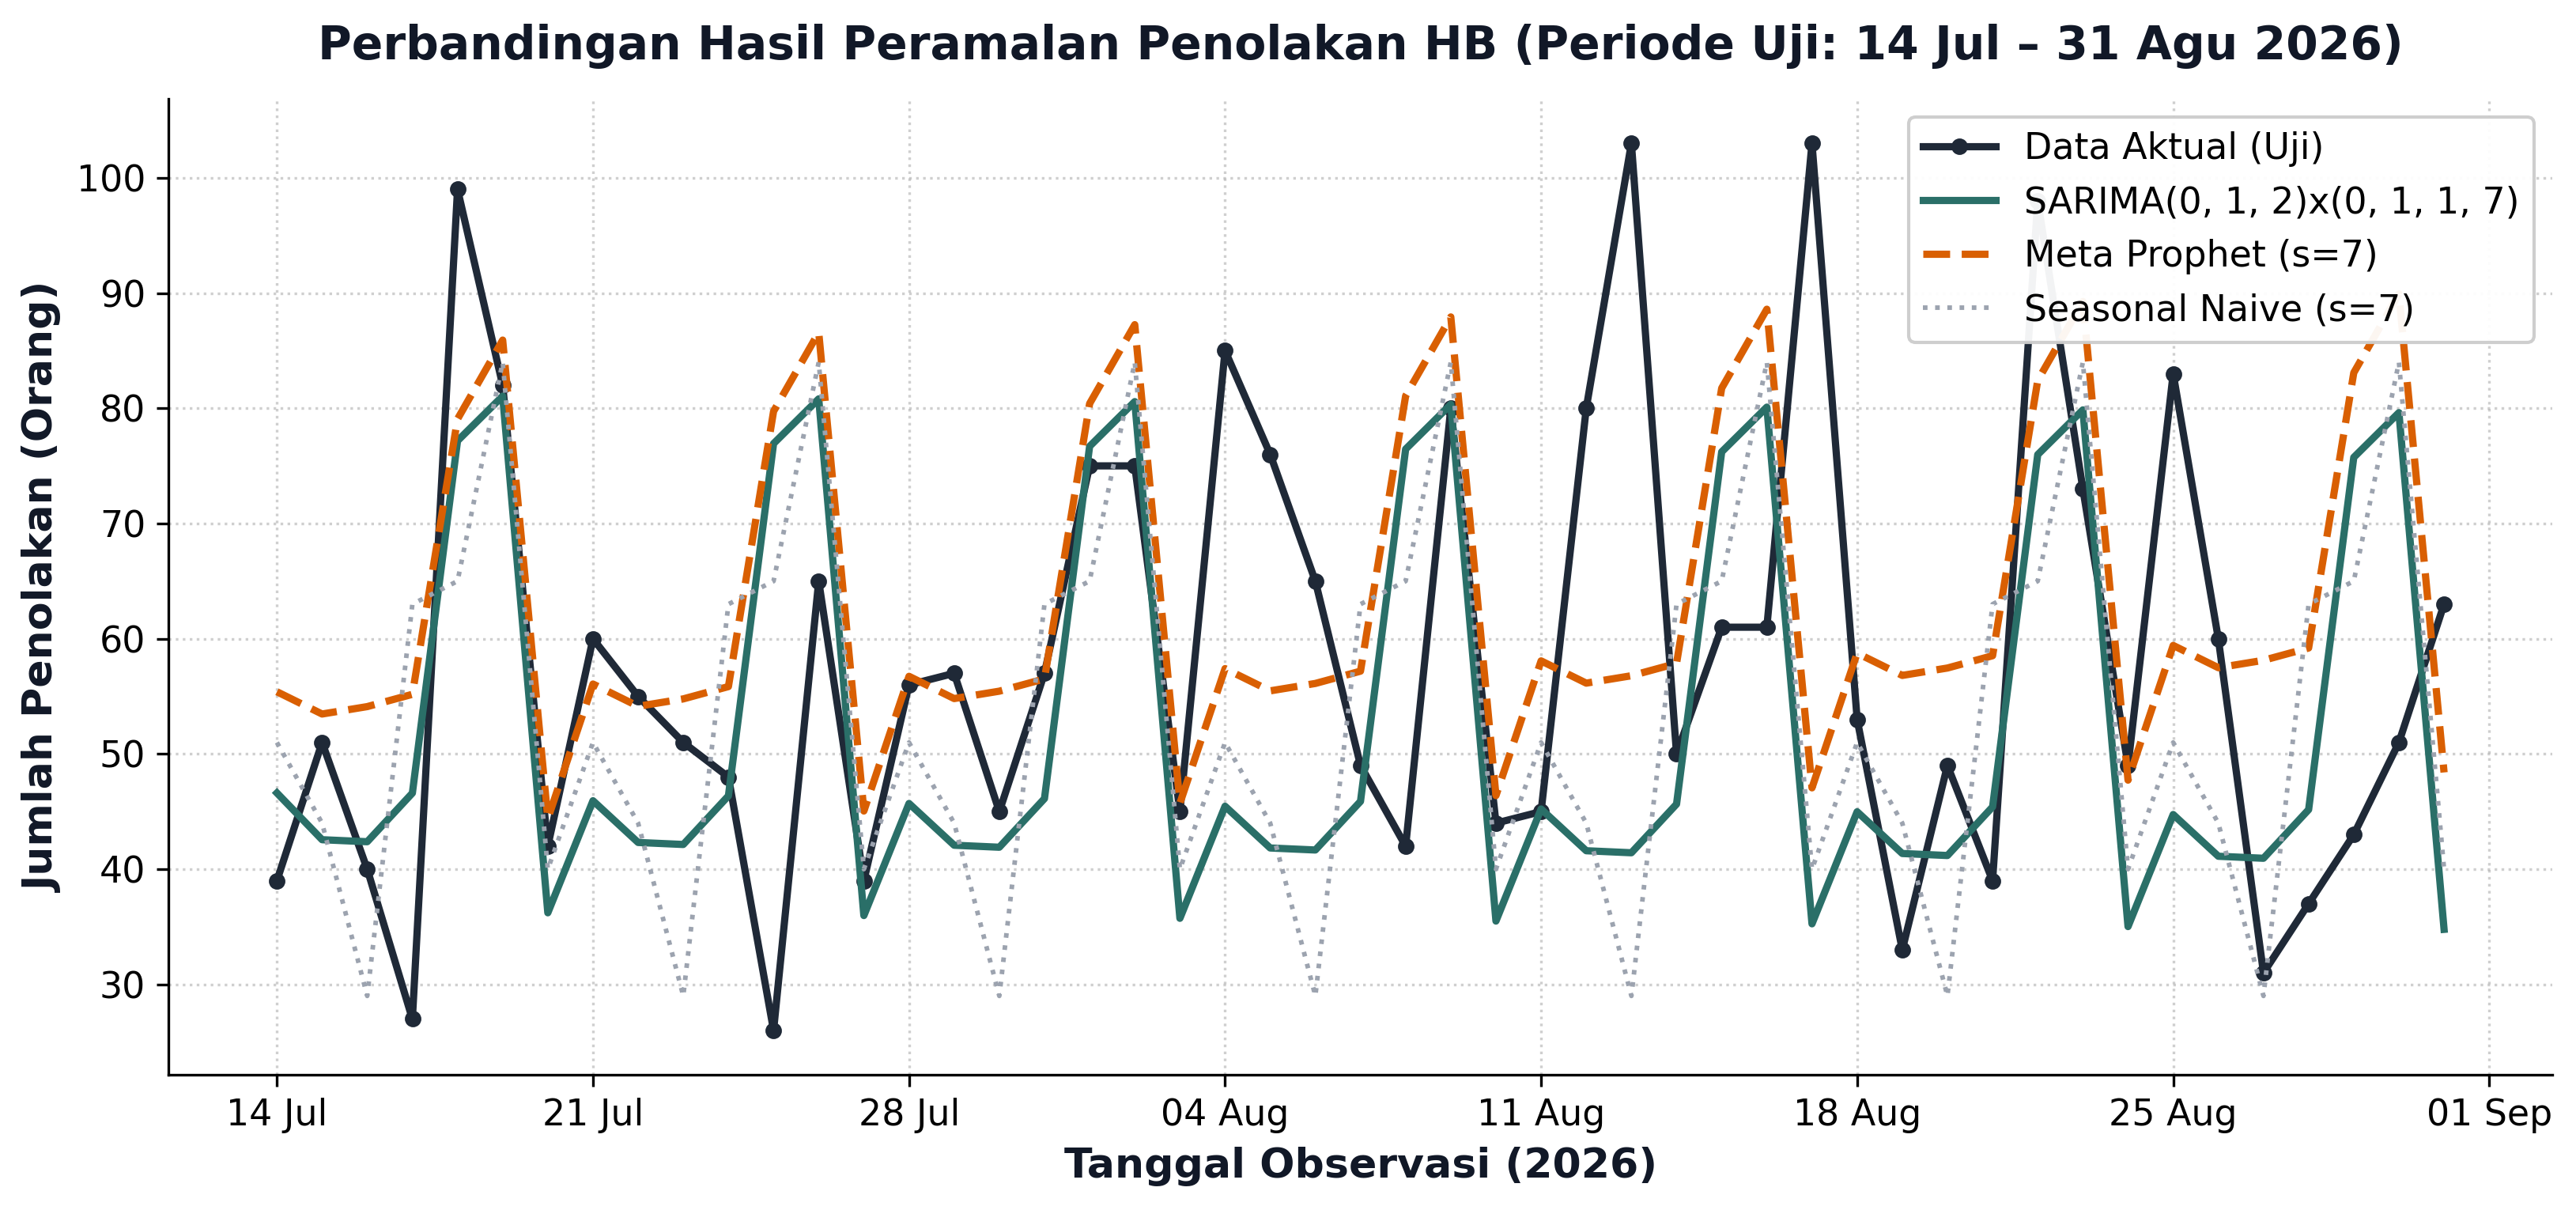

In [6]:
# ==============================================================================
# SEL 5: TABEL PERBANDINGAN METRIK & EKSPOR GRAFIK UNTUK POSTER A1
# ==============================================================================
df_evaluasi = pd.DataFrame([
    {'Model': 'Seasonal Naive (s=7)', **hasil_snaive},
    {'Model': nama_sarima_terbaik, **hasil_sarima},
    {'Model': 'Meta Prophet (s=7)', **hasil_prophet}
])

# Format angka untuk laporan & poster
df_evaluasi_tampil = df_evaluasi.copy()
for col in ['MAE', 'RMSE', 'MASE']:
    df_evaluasi_tampil[col] = df_evaluasi_tampil[col].round(4)

print("=== TABEL EVALUASI KINERJA PERAMALAN (49 HARI UJI) ===")
display(df_evaluasi_tampil)

# Grafik Perbandingan Prediksi untuk Sub-blok 04 Poster A1 (3 Warna Utama)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig, ax = plt.subplots(figsize=(11, 5.2), dpi=300)

tanggal_uji = test_sarima.index

ax.plot(tanggal_uji, y_test, label='Data Aktual (Uji)', color='#1F2937', linewidth=2.2, marker='o', markersize=4)
ax.plot(tanggal_uji, pred_sarima, label=nama_sarima_terbaik, color='#2A6F68', linewidth=2.2, linestyle='-')
ax.plot(tanggal_uji, pred_prophet, label='Meta Prophet (s=7)', color='#D95F02', linewidth=2.2, linestyle='--')
ax.plot(tanggal_uji, pred_snaive, label='Seasonal Naive (s=7)', color='#9CA3AF', linewidth=1.4, linestyle=':')

ax.set_title('Perbandingan Hasil Peramalan Penolakan HB (Periode Uji: 14 Jul – 31 Agu 2026)', fontsize=14, fontweight='bold', pad=12, color='#111827')
ax.set_ylabel('Jumlah Penolakan (Orang)', fontsize=12.5, fontweight='bold', color='#111827')
ax.set_xlabel('Tanggal Observasi (2026)', fontsize=12.5, fontweight='bold', color='#111827')

ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.tick_params(axis='both', labelsize=11)

ax.grid(True, linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95, fontsize=11)

plt.tight_layout()
plt.savefig('grafik_perbandingan_model_subblok04.png', dpi=300, bbox_inches='tight')
plt.show()